In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import load_model
from PIL import Image, ImageOps

print("TensorFlow version:", tf.__version__)
print("Working folder:", Path.cwd())

TensorFlow version: 2.15.0
Working folder: /Users/sashikiran/Desktop/ece-5831-2026-assignments/rock-paper-scissors


In [2]:
model_path = Path("keras_model.h5")
labels_path = Path("labels.txt")

model = load_model(model_path, compile=False)

class_names = []

with labels_path.open("r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()
        if line:
            class_names.append(line.split(maxsplit=1)[1])

print("Model loaded successfully!")
print("Classes:", class_names)
print("Input shape:", model.input_shape)

Model loaded successfully!
Classes: ['Rock', 'Paper', 'Scissors']
Input shape: (None, 224, 224, 3)


In [3]:
def classify_image(image_path):
    image_path = Path(image_path)

    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    with Image.open(image_path) as source:
        original_image = ImageOps.exif_transpose(source).convert("RGB")

    resized_image = ImageOps.fit(
        original_image,
        (224, 224),
        method=Image.Resampling.LANCZOS
    )

    pixels = np.asarray(resized_image, dtype=np.float32)
    normalized_pixels = (pixels / 127.5) - 1.0

    # Shape: (1, 224, 224, 3).
    input_data = np.expand_dims(normalized_pixels, axis=0)

    # Perform forward propagation / inference.
    scores = model.predict(input_data, verbose=0)[0]

    predicted_index = int(np.argmax(scores))
    predicted_class = class_names[predicted_index]
    confidence = float(scores[predicted_index])

    # Show the input image and prediction.
    plt.figure(figsize=(4, 4))
    plt.imshow(original_image)
    plt.title(f"{predicted_class} — {confidence:.2%}")
    plt.axis("off")
    plt.show()

    print("Image:", image_path.name)
    print("Predicted class:", predicted_class)
    print(f"Confidence score: {confidence:.2%}")

    print("\nScores for all classes:")
    for class_name, score in zip(class_names, scores):
        print(f"  {class_name}: {float(score):.2%}")

    return predicted_class, confidence

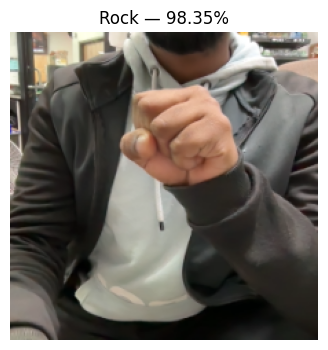

Image: rock.jpg
Predicted class: Rock
Confidence score: 98.35%

Scores for all classes:
  Rock: 98.35%
  Paper: 0.56%
  Scissors: 1.09%


In [4]:
predicted_class, confidence = classify_image("test_images/rock.jpg")

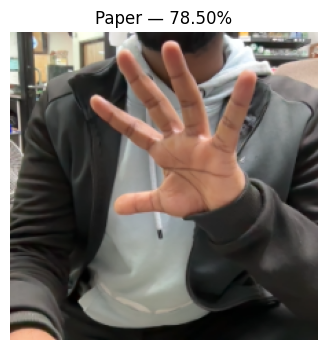

Image: paper.jpg
Predicted class: Paper
Confidence score: 78.50%

Scores for all classes:
  Rock: 0.08%
  Paper: 78.50%
  Scissors: 21.42%


In [5]:
predicted_class, confidence = classify_image("test_images/paper.jpg")

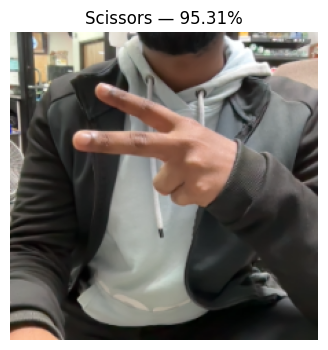

Image: scissors.jpg
Predicted class: Scissors
Confidence score: 95.31%

Scores for all classes:
  Rock: 4.25%
  Paper: 0.44%
  Scissors: 95.31%


In [6]:
predicted_class, confidence = classify_image("test_images/scissors.jpg")